In [1]:
!pip install earthaccess rioxarray xarray netCDF4 -q

import earthaccess
auth = earthaccess.login()  # prompts for your free Earthdata username/password

Enter your Earthdata Login username: mlahari_98765
Enter your Earthdata password: ··········


In [2]:
!pip install spectral -q
!wget -q https://raw.githubusercontent.com/nasa/EMIT-Data-Resources/main/python/modules/emit_tools.py -O emit_tools.py

from emit_tools import emit_xarray

In [7]:
ukai_bbox_search = (73.5880, 21.1825, 73.8880, 21.4825)  # (west, south, east, north) — search format only

results_ukai = earthaccess.search_data(
    short_name="EMITL2ARFL",
    bounding_box=ukai_bbox_search,
    temporal=("2022-07-01", "2026-10-01"),
)
print(f"Ukai granules: {len(results_ukai)}")

Ukai granules: 32


In [8]:
pre_granule = [g for g in results_ukai if "2023-10-04T05:20:54" in str(g['umm']['TemporalExtent']) and float(g['umm'].get('CloudCover', 100)) < 15]
post_granule = [g for g in results_ukai if "2025-04-28T04:27:25" in str(g['umm']['TemporalExtent']) and float(g['umm'].get('CloudCover', 100)) < 15]

print(len(pre_granule), len(post_granule))  # should be 1 1

1 1


In [9]:
import os, gc

os.makedirs("/content/emit_data_ukai/pre", exist_ok=True)
os.makedirs("/content/emit_data_ukai/post", exist_ok=True)

earthaccess.download(pre_granule, "/content/emit_data_ukai/pre")
earthaccess.download(post_granule, "/content/emit_data_ukai/post")

QUEUEING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/2 [00:00<?, ?it/s]

QUEUEING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/3 [00:00<?, ?it/s]

[PosixPath('/content/emit_data_ukai/post/EMIT_L2A_RFL_001_20250428T042725_2511803_009.nc'),
 PosixPath('/content/emit_data_ukai/post/EMIT_L2A_RFLUNCERT_001_20250428T042725_2511803_009.nc'),
 PosixPath('/content/emit_data_ukai/post/EMIT_L2A_MASK_001_20250428T042725_2511803_009.nc')]

In [3]:
def safe_crop(ds, lon_min, lon_max, lat_min, lat_max):
    lat_vals = ds.latitude.values
    lon_vals = ds.longitude.values
    lat_slice = slice(lat_max, lat_min) if lat_vals[0] > lat_vals[-1] else slice(lat_min, lat_max)
    lon_slice = slice(lon_max, lon_min) if lon_vals[0] > lon_vals[-1] else slice(lon_min, lon_max)
    return ds.sel(longitude=lon_slice, latitude=lat_slice)

ukai_bbox = {
    "lon_min": 73.5880, "lon_max": 73.8880,
    "lat_min": 21.1825, "lat_max": 21.4825,
}

In [11]:
import gc

pre_files = os.listdir("/content/emit_data_ukai/pre")
pre_rfl_file = [f for f in pre_files if "RFL" in f and "UNCERT" not in f][0]

ds_pre = emit_xarray(f"/content/emit_data_ukai/pre/{pre_rfl_file}", ortho=True)
pre_crop = safe_crop(ds_pre, **ukai_bbox)
pre_crop.load()

print("PRE shape:", pre_crop.reflectance.shape)
pre_crop.to_netcdf("/content/emit_data_ukai/pre_cropped.nc")

del ds_pre
gc.collect()

PRE shape: (553, 553, 285)


39

In [4]:
import os, gc

post_files = os.listdir("/content/emit_data_ukai/post")
post_rfl_file = [f for f in post_files if "RFL" in f and "UNCERT" not in f][0]

ds_post = emit_xarray(f"/content/emit_data_ukai/post/{post_rfl_file}", ortho=True)
post_crop = safe_crop(ds_post, **ukai_bbox)
post_crop.load()

print("POST shape:", post_crop.reflectance.shape)
post_crop.to_netcdf("/content/emit_data_ukai/post_cropped.nc")

del ds_post
gc.collect()

POST shape: (553, 553, 285)


154

In [6]:
import xarray as xr

pre_crop = xr.open_dataset("/content/emit_data_ukai/pre_cropped.nc")
post_crop = xr.open_dataset("/content/emit_data_ukai/post_cropped.nc")

print(pre_crop.reflectance.shape)
print(post_crop.reflectance.shape)

(553, 553, 285)
(553, 553, 285)


In [7]:
print("Dims order:", pre_crop.reflectance.dims)
print("Latitude size:", pre_crop.sizes.get('latitude'))
print("Longitude size:", pre_crop.sizes.get('longitude'))

Dims order: ('latitude', 'longitude', 'wavelengths')
Latitude size: 553
Longitude size: 553


In [10]:
import xarray as xr
import numpy as np

pre_crop = xr.open_dataset("/content/emit_data_ukai/pre_cropped.nc")
post_crop = xr.open_dataset("/content/emit_data_ukai/post_cropped.nc")

print("PRE  lat range:", float(pre_crop.latitude.min()), "to", float(pre_crop.latitude.max()))
print("PRE  lon range:", float(pre_crop.longitude.min()), "to", float(pre_crop.longitude.max()))
print("POST lat range:", float(post_crop.latitude.min()), "to", float(post_crop.latitude.max()))
print("POST lon range:", float(post_crop.longitude.min()), "to", float(post_crop.longitude.max()))

nan_pct_pre = float(np.isnan(pre_crop.reflectance.values).mean()) * 100
nan_pct_post = float(np.isnan(post_crop.reflectance.values).mean()) * 100
print(f"PRE NaN%: {nan_pct_pre:.2f}")
print(f"POST NaN%: {nan_pct_post:.2f}")

PRE  lat range: 21.182802998477722 to 21.482115349659235
PRE  lon range: 73.58853916781186 to 73.88785151899337
POST lat range: 21.18280299847765 to 21.482115349659164
POST lon range: 73.58853916781194 to 73.88785151899346
PRE NaN%: 0.00
POST NaN%: 0.00


In [11]:
lat_diff = np.abs(pre_crop.latitude.values - post_crop.latitude.values).max()
lon_diff = np.abs(pre_crop.longitude.values - post_crop.longitude.values).max()
print(f"Max lat coordinate difference: {lat_diff}")
print(f"Max lon coordinate difference: {lon_diff}")

Max lat coordinate difference: 7.460698725481052e-14
Max lon coordinate difference: 8.526512829121202e-14


Assign matching coordinates (just to eliminate float precision mismatches downstream) and save final versions

In [12]:
post_aligned = post_crop.assign_coords(latitude=pre_crop.latitude, longitude=pre_crop.longitude)

pre_crop.to_netcdf("/content/emit_data_ukai/pre_final.nc")
post_aligned.to_netcdf("/content/emit_data_ukai/post_final.nc")

print("Both saved, ready for preprocessing.")

Both saved, ready for preprocessing.


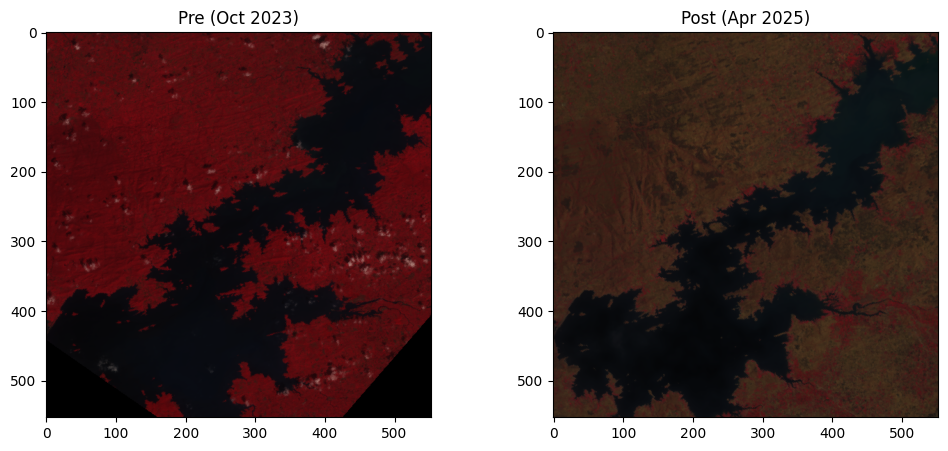

In [13]:
import matplotlib.pyplot as plt

# simple RGB-ish preview using approximate band indices for R/G/B wavelengths
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(pre_crop.reflectance.isel(wavelengths=[60, 40, 20]).values)
axes[0].set_title("Pre (Oct 2023)")
axes[1].imshow(post_aligned.reflectance.isel(wavelengths=[60, 40, 20]).values)
axes[1].set_title("Post (Apr 2025)")
plt.show()

In [45]:

# re-save your key figures (run right after regenerating each plot)
plt.savefig("/content/outputs/RGB.png", dpi=150, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

Band masking (drop known-bad EMIT bands)

In [14]:
import numpy as np

wavelengths = pre_crop.wavelengths.values
print("Number of bands:", len(wavelengths))
print("Wavelength range:", wavelengths.min(), "to", wavelengths.max())

# find indices in the known bad regions
bad_mask = (
    ((wavelengths > 1320) & (wavelengths < 1440)) |
    ((wavelengths > 1800) & (wavelengths < 1950)) |
    (wavelengths < 400) |
    (wavelengths > 2450)
)
print("Bands flagged as bad:", bad_mask.sum(), "out of", len(wavelengths))

Number of bands: 285
Wavelength range: 380.819 to 2492.737
Bands flagged as bad: 45 out of 285


Also drop bands that are bad in practice (near-zero or NaN-heavy across your actual scene)

In [15]:
mean_reflectance_per_band = pre_crop.reflectance.mean(dim=["latitude", "longitude"]).values
low_signal_mask = (mean_reflectance_per_band < 0.001) | np.isnan(mean_reflectance_per_band)

print("Additional low-signal bands found:", low_signal_mask.sum())

final_bad_mask = bad_mask | low_signal_mask
good_band_indices = np.where(~final_bad_mask)[0]
print(f"Keeping {len(good_band_indices)} of {len(wavelengths)} bands")

Additional low-signal bands found: 285
Keeping 0 of 285 bands


Inspect actual reflectance value distribution

In [16]:

vals = pre_crop.reflectance.values
print("Min:", np.nanmin(vals))
print("Max:", np.nanmax(vals))
print("Mean:", np.nanmean(vals))
print("Any NaN:", np.isnan(vals).any())
print("Any -9999 (fill value):", (vals == -9999).any())
print("Count of -9999:", (vals == -9999).sum(), "out of", vals.size)

Min: -9999.0
Max: 1.0201366
Mean: -592.2413
Any NaN: False
Any -9999 (fill value): True
Count of -9999: 5163060 out of 87155565


In [17]:
import numpy as np

wavelengths = pre_crop.wavelengths.values

# known bad wavelength regions
bad_mask = (
    ((wavelengths > 1320) & (wavelengths < 1440)) |
    ((wavelengths > 1800) & (wavelengths < 1950)) |
    (wavelengths < 400) |
    (wavelengths > 2450)
)
print("Bands flagged (known bad regions):", bad_mask.sum())

# mask fill values before computing stats
reflectance_clean = pre_crop.reflectance.where(pre_crop.reflectance != -9999)

mean_reflectance_per_band = reflectance_clean.mean(dim=["latitude", "longitude"], skipna=True).values
low_signal_mask = (mean_reflectance_per_band < 0.001) | np.isnan(mean_reflectance_per_band)
print("Bands flagged (low signal, fill-aware):", low_signal_mask.sum())

final_bad_mask = bad_mask | low_signal_mask
good_band_indices = np.where(~final_bad_mask)[0]
print(f"Keeping {len(good_band_indices)} of {len(wavelengths)} bands")

Bands flagged (known bad regions): 45
Bands flagged (low signal, fill-aware): 37
Keeping 238 of 285 bands


In [18]:
pre_masked = pre_crop.isel(wavelengths=good_band_indices)
post_masked = post_aligned.isel(wavelengths=good_band_indices)

# replace fill values with NaN consistently in both
pre_masked = pre_masked.where(pre_masked.reflectance != -9999)
post_masked = post_masked.where(post_masked.reflectance != -9999)

print(pre_masked.reflectance.shape, post_masked.reflectance.shape)

nan_pct_pre = float(np.isnan(pre_masked.reflectance.values).mean()) * 100
nan_pct_post = float(np.isnan(post_masked.reflectance.values).mean()) * 100
print(f"PRE NaN% after fill-masking: {nan_pct_pre:.2f}")
print(f"POST NaN% after fill-masking: {nan_pct_post:.2f}")

(553, 553, 238) (553, 553, 238)
PRE NaN% after fill-masking: 5.92
POST NaN% after fill-masking: 0.00


Build one combined valid-pixel mask (so pre and post always compare the same pixels)

In [19]:
import numpy as np

pre_valid = ~np.isnan(pre_masked.reflectance.values).any(axis=2)   # True where ALL bands are valid
post_valid = ~np.isnan(post_masked.reflectance.values).any(axis=2)

combined_valid_mask = pre_valid & post_valid

print(f"Valid pixels (both images): {combined_valid_mask.sum()} out of {combined_valid_mask.size} "
      f"({combined_valid_mask.mean()*100:.2f}%)")

Valid pixels (both images): 287693 out of 305809 (94.08%)


Reshape into pixel vectors, keeping only valid pixels

In [20]:
pre_vals = pre_masked.reflectance.values   # shape (553, 553, 238)
post_vals = post_masked.reflectance.values

pre_pixels = pre_vals[combined_valid_mask]    # shape (N_valid, 238)
post_pixels = post_vals[combined_valid_mask]  # shape (N_valid, 238)

print("PRE pixel matrix:", pre_pixels.shape)
print("POST pixel matrix:", post_pixels.shape)

PRE pixel matrix: (287693, 238)
POST pixel matrix: (287693, 238)


Normalize (per-band, fit on pre only — pre is your “training distribution”)

In [21]:
band_mean = pre_pixels.mean(axis=0)
band_std = pre_pixels.std(axis=0)
band_std[band_std == 0] = 1e-8  # avoid divide-by-zero on any flat band

pre_norm = (pre_pixels - band_mean) / band_std
post_norm = (post_pixels - band_mean) / band_std   # same stats applied to post — important, don't refit

print("PRE normalized range:", pre_norm.min(), "to", pre_norm.max())
print("POST normalized range:", post_norm.min(), "to", post_norm.max())

PRE normalized range: -1.9124832 to 21.080372
POST normalized range: -1.906006 to 29.849014


BUild Auto encoder

In [22]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

class Autoencoder(nn.Module):
    def __init__(self, n_bands):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(n_bands, 64), nn.ReLU(),
            nn.Linear(64, 16), nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(16, 64), nn.ReLU(),
            nn.Linear(64, n_bands)
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

n_bands = pre_norm.shape[1]
model = Autoencoder(n_bands).to(device)
print(model)

Using: cpu
Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=238, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=16, bias=True)
    (3): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=16, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=238, bias=True)
  )
)


Prepare training data (train only on PRE — the “normal” baseline)

In [23]:
from torch.utils.data import TensorDataset, DataLoader

pre_tensor = torch.tensor(pre_norm, dtype=torch.float32)
train_dataset = TensorDataset(pre_tensor, pre_tensor)  # autoencoder: input == target
train_loader = DataLoader(train_dataset, batch_size=512, shuffle=True)

Train

In [24]:
import torch.optim as optim

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

n_epochs = 60
model.train()

for epoch in range(n_epochs):
    total_loss = 0.0
    for batch_x, _ in train_loader:
        batch_x = batch_x.to(device)
        optimizer.zero_grad()
        output = model(batch_x)
        loss = criterion(output, batch_x)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch_x.size(0)

    avg_loss = total_loss / len(train_dataset)
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1}/{n_epochs} — loss: {avg_loss:.6f}")

Epoch 1/60 — loss: 0.047880
Epoch 10/60 — loss: 0.000468
Epoch 20/60 — loss: 0.000276
Epoch 30/60 — loss: 0.000233
Epoch 40/60 — loss: 0.000198
Epoch 50/60 — loss: 0.000179
Epoch 60/60 — loss: 0.000172


Run POST through the trained model, get reconstruction error

In [25]:
model.eval()
post_tensor = torch.tensor(post_norm, dtype=torch.float32).to(device)

with torch.no_grad():
    post_reconstructed = model(post_tensor)
    reconstruction_error = torch.mean((post_tensor - post_reconstructed) ** 2, dim=1)

reconstruction_error = reconstruction_error.cpu().numpy()
print("Reconstruction error range:", reconstruction_error.min(), "to", reconstruction_error.max())
print("Mean:", reconstruction_error.mean(), "Std:", reconstruction_error.std())

Reconstruction error range: 0.0026455675 to 5.2390914
Mean: 0.116594106 Std: 0.08000045


Threshold with Otsu’s method

In [26]:
from skimage.filters import threshold_otsu

otsu_thresh = threshold_otsu(reconstruction_error)
print("Otsu threshold:", otsu_thresh)

change_mask_flat = reconstruction_error > otsu_thresh
print(f"Flagged as changed: {change_mask_flat.sum()} out of {len(change_mask_flat)} "
      f"({change_mask_flat.mean()*100:.2f}%)")

Otsu threshold: 0.09469247
Flagged as changed: 189297 out of 287693 (65.80%)


Map the flat pixel results back into 2D spatial form for visualization

In [27]:
import numpy as np

# reconstruct full 2D error map and change mask, filling invalid pixels with NaN
error_map_2d = np.full(combined_valid_mask.shape, np.nan)
change_map_2d = np.full(combined_valid_mask.shape, np.nan)

error_map_2d[combined_valid_mask] = reconstruction_error
change_map_2d[combined_valid_mask] = change_mask_flat.astype(float)

print(error_map_2d.shape)

(553, 553)


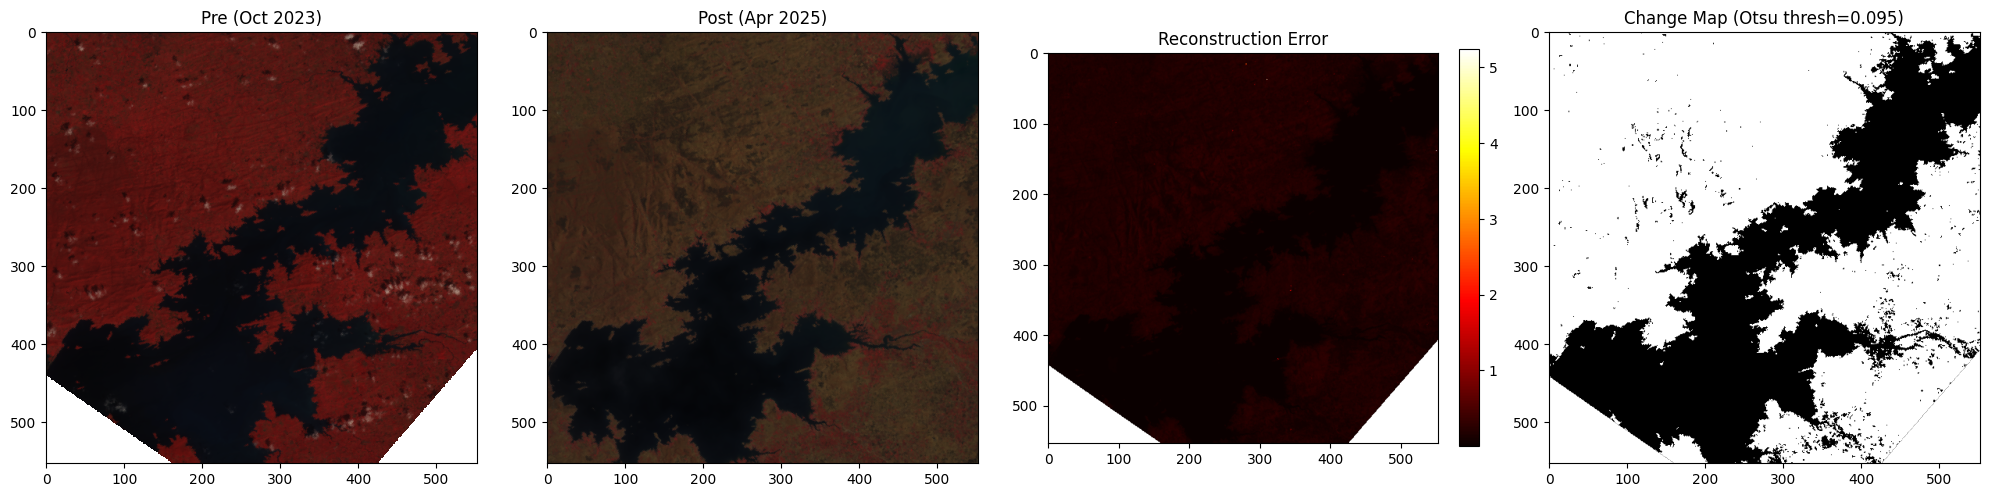

In [28]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(pre_masked.reflectance.isel(wavelengths=[60, 40, 20]).values)
axes[0].set_title("Pre (Oct 2023)")

axes[1].imshow(post_masked.reflectance.isel(wavelengths=[60, 40, 20]).values)
axes[1].set_title("Post (Apr 2025)")

im2 = axes[2].imshow(error_map_2d, cmap='hot')
axes[2].set_title("Reconstruction Error")
plt.colorbar(im2, ax=axes[2], fraction=0.046)

axes[3].imshow(change_map_2d, cmap='gray')
axes[3].set_title(f"Change Map (Otsu thresh={otsu_thresh:.3f})")

plt.tight_layout()
plt.show()

we need to isolate the reservoir from the surrounding land before interpreting “change” as water loss.

Step: Derive a water mask from the PRE image using NDWI

In [29]:
green_idx = np.argmin(np.abs(pre_masked.wavelengths.values - 559))
nir_idx = np.argmin(np.abs(pre_masked.wavelengths.values - 859))

green_band = pre_masked.reflectance.isel(wavelengths=green_idx).values
nir_band = pre_masked.reflectance.isel(wavelengths=nir_idx).values

ndwi = (green_band - nir_band) / (green_band + nir_band + 1e-8)

water_mask_pre = ndwi > 0.0  # standard NDWI water threshold; tune if needed

print(f"Water pixels in PRE: {water_mask_pre.sum()} ({water_mask_pre.mean()*100:.2f}% of scene)")

Water pixels in PRE: 95030 (31.07% of scene)


Visualize the water mask to confirm it traces the reservoir shape

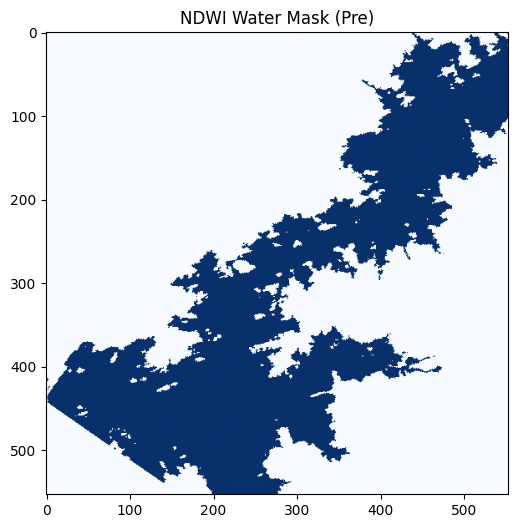

In [30]:
plt.figure(figsize=(6,6))
plt.imshow(water_mask_pre, cmap='Blues')
plt.title("NDWI Water Mask (Pre)")
plt.show()

direct water-extent comparison

In [31]:
green_band_post = post_masked.reflectance.isel(wavelengths=green_idx).values
nir_band_post = post_masked.reflectance.isel(wavelengths=nir_idx).values
ndwi_post = (green_band_post - nir_band_post) / (green_band_post + nir_band_post + 1e-8)
water_mask_post = ndwi_post > 0.0

print(f"Water pixels PRE:  {water_mask_pre.sum()}")
print(f"Water pixels POST: {water_mask_post.sum()}")
print(f"Change: {(water_mask_post.sum() - water_mask_pre.sum())} pixels "
      f"({(water_mask_post.sum()/water_mask_pre.sum() - 1)*100:.1f}% change in surface area)")

Water pixels PRE:  95030
Water pixels POST: 84730
Change: -10300 pixels (-10.8% change in surface area)


Restrict the autoencoder evaluation to the reservoir zone (fixes the vegetation confound)

In [32]:
from scipy.ndimage import binary_dilation

# buffer the pre-water mask outward so we capture the shrinking shoreline, not just core water
water_buffer = binary_dilation(water_mask_pre, iterations=15)

print(f"Buffered zone pixels: {water_buffer.sum()} ({water_buffer.mean()*100:.1f}% of scene)")

Buffered zone pixels: 139742 (45.7% of scene)


In [33]:
# combined_valid_mask was flattening (lat, lon) into a 1D array earlier —
# so we need the buffer mask intersected with combined_valid_mask, then flattened the same way

buffer_and_valid = water_buffer & combined_valid_mask
buffer_flat_within_valid = buffer_and_valid[combined_valid_mask]  # boolean mask over the N_valid pixel array

error_in_zone = reconstruction_error[buffer_flat_within_valid]
print(f"Reconstruction error stats WITHIN reservoir buffer zone:")
print(f"  Mean: {error_in_zone.mean():.4f}, Max: {error_in_zone.max():.4f}")

error_outside_zone = reconstruction_error[~buffer_flat_within_valid]
print(f"Reconstruction error stats OUTSIDE buffer zone (background):")
print(f"  Mean: {error_outside_zone.mean():.4f}, Max: {error_outside_zone.max():.4f}")

Reconstruction error stats WITHIN reservoir buffer zone:
  Mean: 0.0591, Max: 1.4542
Reconstruction error stats OUTSIDE buffer zone (background):
  Mean: 0.1692, Max: 5.2391


Visualize the restricted change map

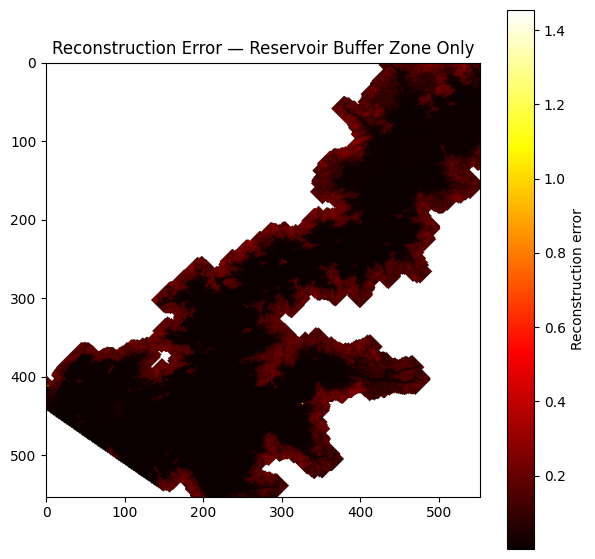

In [34]:
change_map_zone_2d = np.full(combined_valid_mask.shape, np.nan)
error_full = np.full(combined_valid_mask.shape, np.nan)
error_full[combined_valid_mask] = reconstruction_error

# mask everything outside the buffer as NaN (not evaluated)
error_in_buffer_2d = np.where(water_buffer, error_full, np.nan)

plt.figure(figsize=(7,7))
plt.imshow(error_in_buffer_2d, cmap='hot')
plt.colorbar(label="Reconstruction error")
plt.title("Reconstruction Error — Reservoir Buffer Zone Only")
plt.show()

Retrain the autoencoder on water pixels only

In [35]:
# train only on PRE pixels that are water-mask==True, using same combined_valid_mask-indexed arrays
water_mask_pre_valid = water_mask_pre[combined_valid_mask]  # boolean, aligned with pre_pixels/pre_norm rows

pre_water_only = pre_norm[water_mask_pre_valid]
print("Water-only training pixels:", pre_water_only.shape)

Water-only training pixels: (95030, 238)


In [36]:
# rebuild and retrain a fresh model on water-only data
model_water = Autoencoder(n_bands).to(device)

pre_water_tensor = torch.tensor(pre_water_only, dtype=torch.float32)
train_dataset_water = TensorDataset(pre_water_tensor, pre_water_tensor)
train_loader_water = DataLoader(train_dataset_water, batch_size=512, shuffle=True)

optimizer = optim.Adam(model_water.parameters(), lr=1e-3)
criterion = nn.MSELoss()

model_water.train()
for epoch in range(60):
    total_loss = 0.0
    for batch_x, _ in train_loader_water:
        batch_x = batch_x.to(device)
        optimizer.zero_grad()
        output = model_water(batch_x)
        loss = criterion(output, batch_x)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch_x.size(0)
    avg_loss = total_loss / len(train_dataset_water)
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1}/60 — loss: {avg_loss:.6f}")

Epoch 1/60 — loss: 0.124383
Epoch 10/60 — loss: 0.000253
Epoch 20/60 — loss: 0.000191
Epoch 30/60 — loss: 0.000170
Epoch 40/60 — loss: 0.000157
Epoch 50/60 — loss: 0.000141
Epoch 60/60 — loss: 0.000139


Evaluate ALL buffer-zone pixels (not just pre-water ones) through this water-trained model

In [37]:
model_water.eval()

buffer_post_pixels = post_norm[buffer_flat_within_valid]
buffer_post_tensor = torch.tensor(buffer_post_pixels, dtype=torch.float32).to(device)

with torch.no_grad():
    recon = model_water(buffer_post_tensor)
    error_water_model = torch.mean((buffer_post_tensor - recon) ** 2, dim=1).cpu().numpy()

print("Error range:", error_water_model.min(), "to", error_water_model.max())
print("Mean:", error_water_model.mean())

Error range: 0.0028187018 to 5.488876
Mean: 0.22824207


Threshold with Otsu, restricted to the buffer zone

In [38]:
from skimage.filters import threshold_otsu

otsu_thresh_water = threshold_otsu(error_water_model)
print("Otsu threshold (water model):", otsu_thresh_water)

change_mask_water = error_water_model > otsu_thresh_water
print(f"Flagged as changed: {change_mask_water.sum()} out of {len(change_mask_water)} "
      f"({change_mask_water.mean()*100:.2f}%)")

Otsu threshold (water model): 0.42070198
Flagged as changed: 32295 out of 137585 (23.47%)


Map back to 2D and visualize

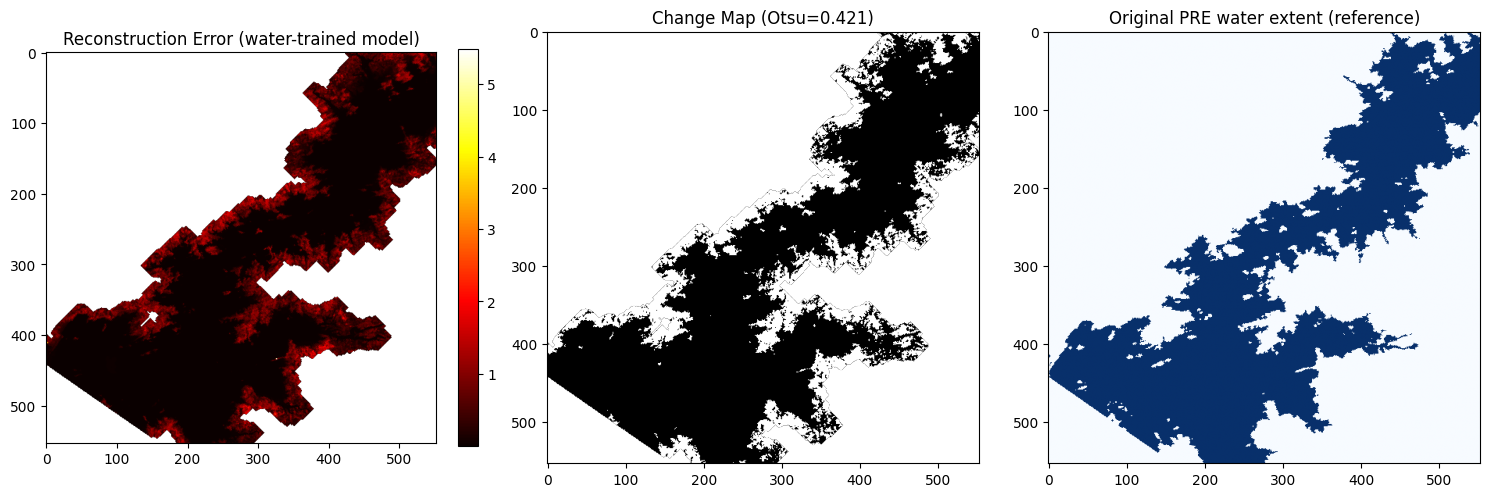

In [39]:
error_water_2d = np.full(combined_valid_mask.shape, np.nan)
change_water_2d = np.full(combined_valid_mask.shape, np.nan)

# buffer_flat_within_valid tells us WHERE in the valid-pixel array the buffer zone pixels are
# error_water_model/change_mask_water are computed only for those buffer pixels
temp_error_full_valid = np.full(combined_valid_mask.sum(), np.nan)
temp_change_full_valid = np.full(combined_valid_mask.sum(), np.nan)

temp_error_full_valid[buffer_flat_within_valid] = error_water_model
temp_change_full_valid[buffer_flat_within_valid] = change_mask_water.astype(float)

error_water_2d[combined_valid_mask] = temp_error_full_valid
change_water_2d[combined_valid_mask] = temp_change_full_valid

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
im0 = axes[0].imshow(error_water_2d, cmap='hot')
axes[0].set_title("Reconstruction Error (water-trained model)")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

axes[1].imshow(change_water_2d, cmap='gray')
axes[1].set_title(f"Change Map (Otsu={otsu_thresh_water:.3f})")

axes[2].imshow(water_mask_pre, cmap='Blues')
axes[2].set_title("Original PRE water extent (reference)")

plt.tight_layout()
plt.show()

In [46]:

# re-save your key figures (run right after regenerating each plot)
plt.savefig("/content/outputs/comparision.png", dpi=150, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

Compare autoencoder-flagged change count to the NDWI number
python

In [40]:
ae_flagged_count = change_mask_water.sum()
ndwi_change_count = 95030 - 84730  # from earlier NDWI comparison

print(f"Autoencoder flagged (within buffer): {ae_flagged_count} pixels")
print(f"NDWI-measured water loss: {ndwi_change_count} pixels")
print(f"Ratio: {ae_flagged_count / ndwi_change_count:.2f}")

Autoencoder flagged (within buffer): 32295 pixels
NDWI-measured water loss: 10300 pixels
Ratio: 3.14


Evaluate only on pixels that WERE water in pre — no buffer dilation

In [41]:
# use the SAME pixel set as training (water_mask_pre_valid), evaluated on POST instead of PRE
pre_water_pixels_post_values = post_norm[water_mask_pre_valid]
print("Evaluating on:", pre_water_pixels_post_values.shape, "pixels (all former water)")

post_water_tensor = torch.tensor(pre_water_pixels_post_values, dtype=torch.float32).to(device)

with torch.no_grad():
    recon = model_water(post_water_tensor)
    error_former_water = torch.mean((post_water_tensor - recon) ** 2, dim=1).cpu().numpy()

print("Error range:", error_former_water.min(), "to", error_former_water.max())
print("Mean:", error_former_water.mean())

Evaluating on: (95030, 238) pixels (all former water)
Error range: 0.0028187018 to 1.675769
Mean: 0.042199172


Threshold and compare directly to the NDWI number

In [42]:
otsu_thresh_final = threshold_otsu(error_former_water)
change_mask_final = error_former_water > otsu_thresh_final

print("Otsu threshold:", otsu_thresh_final)
print(f"Flagged as 'no longer water': {change_mask_final.sum()} out of {len(change_mask_final)} "
      f"({change_mask_final.mean()*100:.2f}%)")

ndwi_change_count = 95030 - 84730
print(f"NDWI-measured water loss: {ndwi_change_count} pixels ({ndwi_change_count/95030*100:.2f}% of pre-water)")
print(f"Autoencoder-flagged ratio vs NDWI: {change_mask_final.sum() / ndwi_change_count:.2f}")

Otsu threshold: 0.20867
Flagged as 'no longer water': 6189 out of 95030 (6.51%)
NDWI-measured water loss: 10300 pixels (10.84% of pre-water)
Autoencoder-flagged ratio vs NDWI: 0.60


Visualize — this time it should show a clean shoreline ring, not a blob

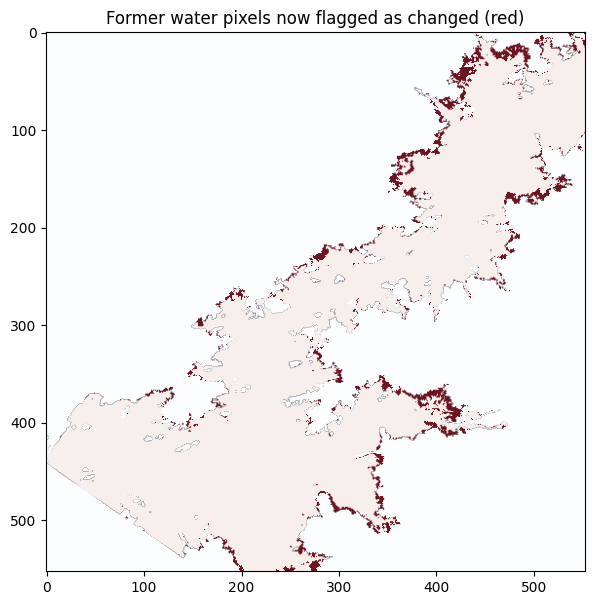

In [43]:
change_final_2d = np.full(combined_valid_mask.shape, np.nan)
temp = np.full(combined_valid_mask.sum(), np.nan)
temp[water_mask_pre_valid] = change_mask_final.astype(float)
change_final_2d[combined_valid_mask] = temp

plt.figure(figsize=(7,7))
plt.imshow(water_mask_pre, cmap='Blues', alpha=0.3)
plt.imshow(change_final_2d, cmap='Reds', alpha=0.9)
plt.title("Former water pixels now flagged as changed (red)")
plt.show()

In [44]:
# save the key plots you already generated, if not already saved as files
import os
os.makedirs("/content/outputs", exist_ok=True)

# re-save your key figures (run right after regenerating each plot)
plt.savefig("/content/outputs/final_overlay.png", dpi=150, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>